<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Risk/EVT_VaR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
# Steps
'''
1. Generate data from t student(with known parameters we will know the tail index)
2. Make losses
3. Above a threshold, get excess losses
4. Fit the GPD
'''

import numpy as np
import pandas as pd
from scipy.stats import genpareto, t, probplot
import matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt

In [19]:
nu = 4
big = t.rvs(nu, size=100000, random_state=np.random.default_rng(0))
#plt.hist(big, bins=10000)
L0 = -big
u0 = np.quantile(L0, 0.99)
xi0 ,_, _ = genpareto.fit(L0[L0 > u0] - u0, floc=0)
print(f"t(nu=4) data: fitted xi = {xi0:.3f}   theory 1/nu = {1/4:.3f}")

t(nu=4) data: fitted xi = 0.186   theory 1/nu = 0.250


In [24]:
# Download and close prices/returns data for a time period
years = 15
start_date = dt.datetime.today() - dt.timedelta(days=365*years)
end_date = dt.datetime.today()
#start_date = '2008-04-28'
#end_date = '2023-04-25'

tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close = pd.DataFrame()

for ticker in tickers:
  # Use multi_level_index=False to prevent MultiIndex columns and retrieve the adjusted 'Close'
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
  adj_close[ticker] = data['Close']

# Log Returns
log_ret = np.log(adj_close / adj_close.shift(1))
log_ret.dropna(inplace=True)

# Portfolio
# Weighing equally weighted
weights = np.array([1/len(tickers)]*len(tickers))

# Portfolio historical returns
p_ret = (log_ret * weights).sum(axis=1)

/tmp/ipykernel_711/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_711/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_711/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_711/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_in

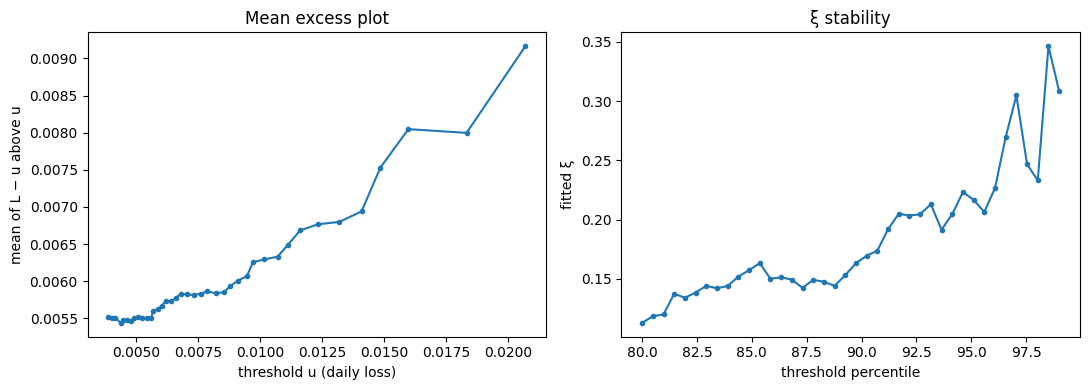

80%  u = 0.390%  excesses =  754  xi = 0.113
82%  u = 0.465%  excesses =  662  xi = 0.138
85%  u = 0.544%  excesses =  570  xi = 0.157
87%  u = 0.620%  excesses =  478  xi = 0.142
90%  u = 0.734%  excesses =  387  xi = 0.163
92%  u = 0.881%  excesses =  295  xi = 0.203
95%  u = 1.071%  excesses =  203  xi = 0.223
97%  u = 1.409%  excesses =  112  xi = 0.305


In [25]:
x = p_ret.values
L = -x                                          # daily losses: crash days are large positive numbers

qs = np.linspace(0.80, 0.99, 40)                # 40 candidate threshold levels, 80th to 99th percentile
us = np.quantile(L, qs)                         # the loss value at each of those levels

mean_excess = [np.mean(L[L > u] - u) for u in us]
xis = [genpareto.fit(L[L > u] - u, floc=0)[0] for u in us]
n_exc = [(L > u).sum() for u in us]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(us, mean_excess, "o-", ms=3)
ax[0].set_title("Mean excess plot")
ax[0].set_xlabel("threshold u (daily loss)")
ax[0].set_ylabel("mean of L − u above u")

ax[1].plot(qs * 100, xis, "o-", ms=3)
ax[1].set_title("ξ stability")
ax[1].set_xlabel("threshold percentile")
ax[1].set_ylabel("fitted ξ")
plt.tight_layout(); plt.show()

for q, u, k, xi_ in zip(qs[::5], us[::5], n_exc[::5], xis[::5]):
    print(f"{q:.0%}  u = {u:.3%}  excesses = {k:4d}  xi = {xi_:.3f}")